## Random Forest Model

For complex financial modeling, standard linear approaches often fall short when capturing non-linear interactions across accounting ratios. To address this, we implement a Random Forest classifier—an ensemble learning method based on bootstrap aggregating (bagging) over decision trees. Random Forest constructs a forest of uncorrelated decision trees during training, where each individual tree is built using a random bootstrap sample of the training data (bagging) and evaluates a random subset of features at each candidate split point ($m \approx \sqrt{p}$). The final class prediction is determined via a majority vote across all trees in the ensemble. The voting mechanism is formalized below:

$$\hat{y} = \text{mode} \left( \{ T_1(x), T_2(x), \dots, T_B(x) \} \right)$$

Where $B$ is the total number of trees, $x$ represents the feature vector of a given company, and $T_b(x)$ is the class output of the $b$-th decision tree.The architecture of Random Forest provides several distinct structural benefits for our dataset:

- __Invariance to Feature Scaling and Outliers__: Unlike logistic regression, decision trees segment data using rank-based inequality checks (e.g., $X_j > \theta$). Because tree splits depend solely on the relative ordering of values rather than their absolute distance from a mean or median, extreme outliers in financial ratios (such as Attr27 or Attr55) do not distort model boundaries. Consequently, explicit scaling transformations like StandardScaler or aggressive outlier trimming are not required for tree stability.

- __Native Handling of Non-Linearity and Multicollinearity__: Financial distress rarely stems from a single accounting metric in isolation; it is driven by complex interactions between leverage, liquidity, and operational performance. Random Forest captures high-order feature interactions natively without manual polynomial expansion. Furthermore, because each tree selects from a random subspace of features, multicollinear variables (such as related liquidity indicators) do not degrade model stability as they do in unregularized linear models.

- __Resistance to Overfitting via Ensembling__: While individual decision trees are prone to high variance and overfitting noisy financial data, averaging the predictions of hundreds of decorrelated trees significantly reduces overall model variance while maintaining low bias.

In [42]:
# Libraries used for Machine Learning Models:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import xgboost as xgb

In [43]:
X_train_tree = pd.read_csv('X_train_tree.csv')
X_test_tree = pd.read_csv('X_test_tree.csv')

X_train_xgboost = pd.read_csv('X_train_xgboost.csv')
X_test_xgboost = pd.read_csv('X_test_xgboost.csv')

y_train = pd.read_csv('y_train.csv').squeeze()
y_test = pd.read_csv('y_test.csv').squeeze()

print(f"X_train_tree shape: {X_train_tree.shape}")
print(f"X_train_xgboost shape: {X_train_xgboost.shape}")    
print(f'Train Class Balance:\n{y_train.value_counts(normalize=True).round(4)}')

X_train_tree shape: (8332, 108)
X_train_xgboost shape: (8332, 64)
Train Class Balance:
class
0    0.9527
1    0.0473
Name: proportion, dtype: float64


In [44]:
# %%
# Setting sampling_strategy to 30/70 (~0.4286)
smote = SMOTE(sampling_strategy=30/70, random_state=2004)
X_train_smote, y_train_smote = smote.fit_resample(X_train_tree, y_train)

# Verification
print("Class counts after SMOTE (30:70 ratio):")
print(y_train_smote.value_counts())

print("\nClass percentages after SMOTE:")
print(y_train_smote.value_counts(normalize=True).round(4))

Class counts after SMOTE (30:70 ratio):
class
0    7938
1    3402
Name: count, dtype: int64

Class percentages after SMOTE:
class
0    0.7
1    0.3
Name: proportion, dtype: float64


       RANDOM FOREST PERFORMANCE (ORIG)   
ROC-AUC Score : 0.8392
PR-AUC Score  : 0.3752

Classification Report:

              precision    recall  f1-score   support

           0     0.9637    0.9909    0.9771      1985
           1     0.5814    0.2525    0.3521        99

    accuracy                         0.9559      2084
   macro avg     0.7726    0.6217    0.6646      2084
weighted avg     0.9456    0.9559    0.9475      2084



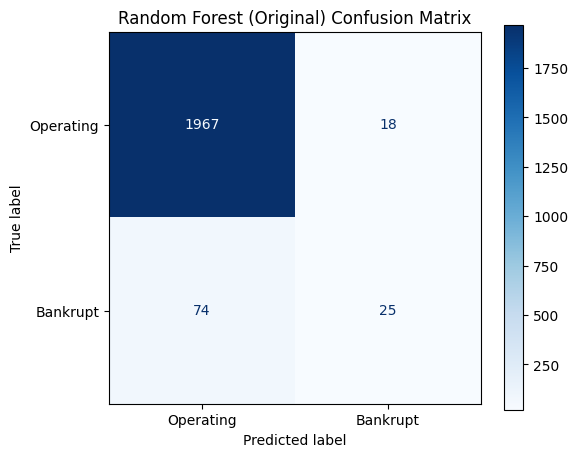

In [46]:
# ## 1B. Random Forest Classifier (Original - class_weight='balanced')

# %%
rf_clf_orig = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight='balanced',
    random_state=2004,
    n_jobs=-1
)

rf_clf_orig.fit(X_train_tree, y_train)

y_pred_rf_orig  = rf_clf_orig.predict(X_test_tree)
y_proba_rf_orig = rf_clf_orig.predict_proba(X_test_tree)[:, 1]

print("==========================================")
print("       RANDOM FOREST PERFORMANCE (ORIG)   ")
print("==========================================")
print(f"ROC-AUC Score : {roc_auc_score(y_test, y_proba_rf_orig):.4f}")
print(f"PR-AUC Score  : {average_precision_score(y_test, y_proba_rf_orig):.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf_orig, digits=4))

fig, ax = plt.subplots(figsize=(6, 5))
cm_rf_orig = confusion_matrix(y_test, y_pred_rf_orig)
disp_rf_orig = ConfusionMatrixDisplay(confusion_matrix=cm_rf_orig, display_labels=['Operating', 'Bankrupt'])
disp_rf_orig.plot(cmap='Blues', ax=ax)
plt.title('Random Forest (Original) Confusion Matrix', fontsize=12)
plt.show()

### Random Forest Performance (Original):

For our Random Forest model trained on the original, un-resampled dataset, we obtained solid overall ranking metrics with an ROC-AUC score of 83.92% and a PR-AUC score of 37.52%. Examining the confusion matrix reveals how the model handled the test set's 2,084 total observations.

- True Negatives: 1,967 healthy operating firms were correctly identified as operating.

- False Positives: 18 operating firms were incorrectly flagged as bankrupt (false alarms).

- False Negatives: 74 bankrupt firms were misclassified as operating (missed bankruptcies).

- True Positives: 25 bankrupt firms were correctly identified.

Looking at these counts in terms of classification trade-offs, out of the 43 total companies flagged as bankrupt, 25 actually failed, yielding a solid precision of 58.14%. However, because the model missed 74 of the 99 true bankruptcies, its recall reached only 25.25%. While the model demonstrates strong specificity and avoids flooding the user with false positives, its high false-negative rate highlights a conservative decision boundary that struggles to detect subtle bankruptcy signals without resampling support.

       RANDOM FOREST PERFORMANCE (SMOTE)  
ROC-AUC Score : 0.8545
PR-AUC Score  : 0.4277

Classification Report:

              precision    recall  f1-score   support

           0     0.9651    0.9899    0.9774      1985
           1     0.5833    0.2828    0.3810        99

    accuracy                         0.9563      2084
   macro avg     0.7742    0.6364    0.6792      2084
weighted avg     0.9470    0.9563    0.9490      2084



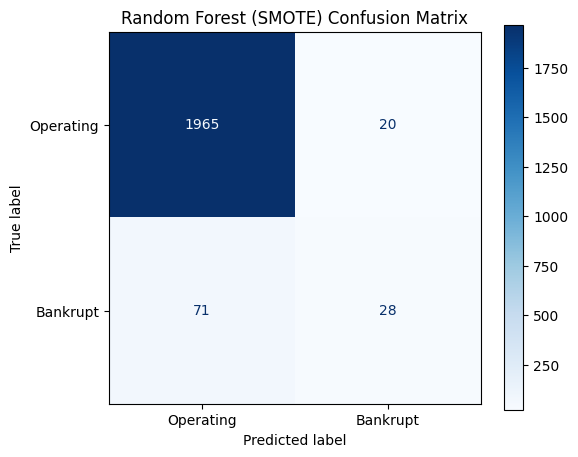

In [58]:
# ## 1A. Random Forest Classifier (with SMOTE)

# %%
rf_clf_smote = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    random_state=2004,
    n_jobs=-1
)

rf_clf_smote.fit(X_train_smote, y_train_smote)

y_pred_rf_smote  = rf_clf_smote.predict(X_test_tree)
y_proba_rf_smote = rf_clf_smote.predict_proba(X_test_tree)[:, 1]

print("==========================================")
print("       RANDOM FOREST PERFORMANCE (SMOTE)  ")
print("==========================================")
print(f"ROC-AUC Score : {roc_auc_score(y_test, y_proba_rf_smote):.4f}")
print(f"PR-AUC Score  : {average_precision_score(y_test, y_proba_rf_smote):.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf_smote, digits=4))

fig, ax = plt.subplots(figsize=(6, 5))
cm_rf_smote = confusion_matrix(y_test, y_pred_rf_smote)
disp_rf_smote = ConfusionMatrixDisplay(confusion_matrix=cm_rf_smote, display_labels=['Operating', 'Bankrupt'])
disp_rf_smote.plot(cmap='Blues', ax=ax)
plt.title('Random Forest (SMOTE) Confusion Matrix', fontsize=12)
plt.show()

### Random Forest Performance (SMOTE):

When evaluating our Random Forest model trained with SMOTE oversampling, we observed a noticeable improvement in minority-class detection, achieving an ROC-AUC score of 85.45% and a PR-AUC score of 42.77%. The corresponding confusion matrix demonstrates the direct impact of synthetic balancing.

- True Negatives: 1,965 operating firms were correctly classified.

- False Positives: 20 operating firms were falsely predicted to go bankrupt (only 2 more false alarms than the original model).

- False Negatives: 71 bankrupt firms were missed and misclassified as operating (a reduction of 3 missed cases).

- True Positives: 28 bankrupt firms were accurately identified.

By generating synthetic minority samples prior to training, SMOTE shifted the decision boundary to capture more true positive bankruptcies (increasing true positives from 25 to 28) and driving recall up to 28.28% (compared to 25.25% on the original data). Crucially, this gain in recall came at virtually no cost to precision: with 28 true positives out of 48 total positive predictions, the model maintained a strong precision of 58.33%. Overall, combining SMOTE with Random Forest successfully mitigated majority-class bias, yielding a better balance between catching corporate failure and suppressing false alarms.

## XGBoost Model

To achieve maximum predictive power and capture subtle failure signals within highly imbalanced data, we deploy XGBoost (Extreme Gradient Boosting)—an optimized, scalable implementation of gradient-boosted decision trees. Unlike Random Forest, which builds trees independently in parallel, XGBoost builds trees sequentially in an additive, iterative fashion. Each consecutive tree is trained specifically to predict the residual errors (gradients) of all prior trees combined. The objective function optimized at step $t$ balances empirical loss minimization against model complexity:

$$\mathcal{L}^{(t)} = \sum_{i=1}^{n} l\left(y_i, \hat{y}_i^{(t-1)} + f_t(x_i)\right) + \Omega(f_t)$$

Where $l$ represents the convex loss function (e.g., binary logistic loss), $f_t(x_i)$ is the new tree added at step $t$, and $\Omega(f_t) = \gamma T + \frac{1}{2}\lambda \sum_{j=1}^{T} w_j^2$ is a regularization term that penalizes tree complexity, total leaf nodes ($T$), and leaf weights ($w$). XGBoost offers several key capabilities tailored to our bankruptcy prediction task:

- __Gradient-Based Optimization for Rare Events__: By fitting new trees directly to the negative gradient of the loss function, XGBoost continuously directs model capacity toward hard-to-classify samples. In our dataset, where bankruptcies comprise only $4.7\%$ of observations, this targeted residual learning prevents the model from being overwhelmed by the operating majority class.

- __Native Class Imbalance Balancing (scale_pos_weight)__: XGBoost incorporates a dedicated hyperparameter, scale_pos_weight, which scales the gradient step for positive instances (Class 1). This heavily penalizes misclassifications of minority bankrupt companies directly within the loss function without needing to manipulate the underlying data distribution.

- __Built-in Regularization and Exact Greedy Splitting__: To combat overfitting on small, noisy minority classes, XGBoost integrates both $L_1$ (Lasso) and $L_2$ (Ridge) regularization ($\Omega$) on leaf weights. Additionally, its exact greedy algorithm handles missing values natively by learning optimal default split directions for incomplete features (such as missingindicator_Attr27), turning missingness patterns into strong predictive signals rather than data quality issues.

         XGBOOST PERFORMANCE (ORIGINAL)   
ROC-AUC Score : 0.8927
PR-AUC Score  : 0.5313

Classification Report:

              precision    recall  f1-score   support

           0     0.9744    0.9763    0.9753      1985
           1     0.5053    0.4848    0.4948        99

    accuracy                         0.9530      2084
   macro avg     0.7398    0.7306    0.7351      2084
weighted avg     0.9521    0.9530    0.9525      2084



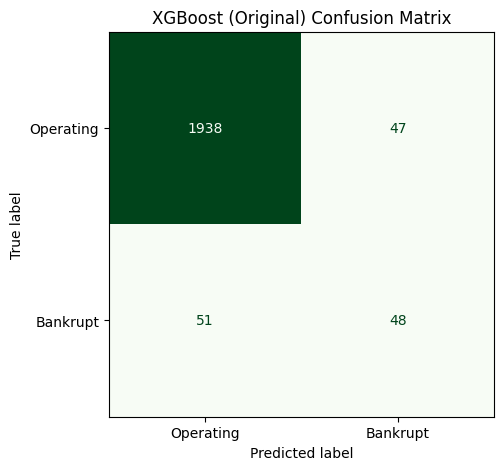

In [54]:
# ## 2B. XGBoost Classifier (Original - scale_pos_weight)

# %%
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_clf_orig = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    random_state=2004,
    eval_metric='logloss'
)

xgb_clf_orig.fit(X_train_xgboost, y_train)

y_pred_xgb_orig  = xgb_clf_orig.predict(X_test_xgboost)
y_proba_xgb_orig = xgb_clf_orig.predict_proba(X_test_xgboost)[:, 1]

print("==========================================")
print("         XGBOOST PERFORMANCE (ORIGINAL)   ")
print("==========================================")
print(f"ROC-AUC Score : {roc_auc_score(y_test, y_proba_xgb_orig):.4f}")
print(f"PR-AUC Score  : {average_precision_score(y_test, y_proba_xgb_orig):.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_xgb_orig, digits=4))

fig, ax = plt.subplots(figsize=(6, 5))
cm_xgb_orig = confusion_matrix(y_test, y_pred_xgb_orig)
disp_xgb_orig = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_orig, display_labels=['Operating', 'Bankrupt'])
disp_xgb_orig.plot(cmap='Greens', ax=ax, colorbar=False)
plt.title('XGBoost (Original) Confusion Matrix', fontsize=12)
plt.show()

### XGBoost Performance (Original):

For our XGBoost model trained on the original dataset, we observed a substantial jump in overall ranking performance, achieving an ROC-AUC score of 89.27% and a PR-AUC score of 53.13%.

- True Negatives: 1,938 operating firms were correctly classified.

- False Positives: 47 operating firms were falsely flagged as bankrupt (false alarms).

- False Negatives: 51 bankrupt firms were misclassified as operating (missed bankruptcies).

- True Positives: 48 bankrupt firms were accurately identified.

Compared to the Random Forest models, standard XGBoost nearly doubled the minority-class recovery rate, pushing recall up to 48.48% by correctly identifying 48 out of 99 true bankruptcies. However, this aggressive detection strategy came with a trade-off in precision: with 47 false alarms alongside 48 true positives, the model’s precision dropped to 50.53%. Nevertheless, this balanced trade-off across both classes yielded a strong minority-class F1-score of 0.4948, proving that gradient boosting natively handles severe class imbalance far better than standard decision tree ensembles without requiring artificial resampling.

         XGBOOST PERFORMANCE (SMOTE)      
ROC-AUC Score : 0.8933
PR-AUC Score  : 0.5185

Classification Report:

              precision    recall  f1-score   support

           0     0.9721    0.9844    0.9782      1985
           1     0.5811    0.4343    0.4971        99

    accuracy                         0.9583      2084
   macro avg     0.7766    0.7094    0.7377      2084
weighted avg     0.9536    0.9583    0.9554      2084



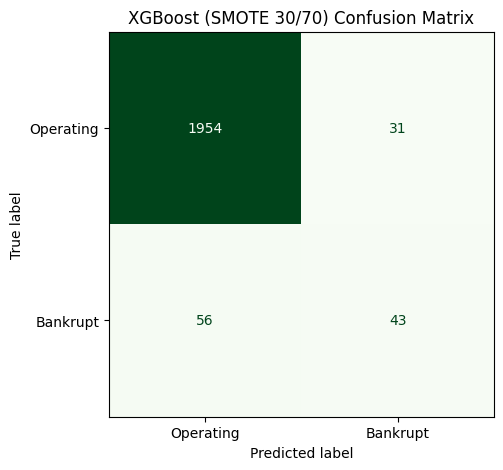

In [57]:
# ## 2A. XGBoost Classifier (with 30/70 SMOTE)

# %%
xgb_clf_smote = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=70 / 30,  # Balances the remaining 70/30 class ratio from SMOTE
    random_state=2004,
    eval_metric='logloss'
)

xgb_clf_smote.fit(X_train_smote, y_train_smote)

y_pred_xgb_smote  = xgb_clf_smote.predict(X_test_tree)
y_proba_xgb_smote = xgb_clf_smote.predict_proba(X_test_tree)[:, 1]

print("==========================================")
print("         XGBOOST PERFORMANCE (SMOTE)      ")
print("==========================================")
print(f"ROC-AUC Score : {roc_auc_score(y_test, y_proba_xgb_smote):.4f}")
print(f"PR-AUC Score  : {average_precision_score(y_test, y_proba_xgb_smote):.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_xgb_smote, digits=4))

fig, ax = plt.subplots(figsize=(6, 5))
cm_xgb_smote = confusion_matrix(y_test, y_pred_xgb_smote)
disp_xgb_smote = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_smote, display_labels=['Operating', 'Bankrupt'])
disp_xgb_smote.plot(cmap='Greens', ax=ax, colorbar=False)
plt.title('XGBoost (SMOTE 30/70) Confusion Matrix', fontsize=12)
plt.show()

### XGBoost Performance (SMOTE):

Training the XGBoost model on the SMOTE-resampled (30/70 ratio) dataset yielded the highest overall discrimination threshold in our benchmark, reaching an ROC-AUC score of 89.33% alongside a solid PR-AUC score of 51.85%.

- True Negatives: 1,954 operating firms were correctly identified.

- False Positives: 31 operating firms were falsely predicted to go bankrupt (a significant 16-case reduction in false alarms compared to the unsampled XGBoost model).

- False Negatives: 56 bankrupt firms were missed by the model.

- True Positives: 43 bankrupt firms were correctly captured.

Applying SMOTE helped temper XGBoost's false-positive tendencies, reducing false alarms from 47 down to 31. This refined boundary elevated minority-class precision to 58.11% (43 true positives out of 74 total positive predictions) while maintaining a strong recall of 43.43%. Consequently, XGBoost with SMOTE achieved our best balance of precision and recall for minority prediction, culminating in a top-performing F1-score of 0.4971 on the bankruptcy class.

## Threshold

In [49]:
# ## 3. Threshold Comparison: Original vs. SMOTE XGBoost

# %%
thresholds = [0.15, 0.20, 0.25, 0.30, 0.50]

print("="*80)
print("                    THRESHOLD ANALYSIS: ORIGINAL XGBOOST                    ")
print("="*80)
print(f"{'Threshold':<10} | {'Recall (Class 1)':<18} | {'Precision (Class 1)':<20} | {'Bankrupt Caught':<15}")
print("-" * 80)

for t in thresholds:
    y_pred_custom = (y_proba_xgb_orig >= t).astype(int)
    cm = confusion_matrix(y_test, y_pred_custom)
    tp, fn, fp = cm[1, 1], cm[1, 0], cm[0, 1]
    recall = tp / (tp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    print(f"{t:<10.2f} | {recall:<18.2%} | {precision:<20.2%} | {tp}/{tp+fn}")

print("\n" + "="*80)
print("                      THRESHOLD ANALYSIS: SMOTE XGBOOST                     ")
print("="*80)
print(f"{'Threshold':<10} | {'Recall (Class 1)':<18} | {'Precision (Class 1)':<20} | {'Bankrupt Caught':<15}")
print("-" * 80)

for t in thresholds:
    y_pred_custom = (y_proba_xgb_smote >= t).astype(int)
    cm = confusion_matrix(y_test, y_pred_custom)
    tp, fn, fp = cm[1, 1], cm[1, 0], cm[0, 1]
    recall = tp / (tp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    print(f"{t:<10.2f} | {recall:<18.2%} | {precision:<20.2%} | {tp}/{tp+fn}")

                    THRESHOLD ANALYSIS: ORIGINAL XGBOOST                    
Threshold  | Recall (Class 1)   | Precision (Class 1)  | Bankrupt Caught
--------------------------------------------------------------------------------
0.15       | 80.81%             | 19.66%               | 80/99
0.20       | 74.75%             | 22.56%               | 74/99
0.25       | 67.68%             | 25.48%               | 67/99
0.30       | 60.61%             | 30.61%               | 60/99
0.50       | 48.48%             | 50.53%               | 48/99

                      THRESHOLD ANALYSIS: SMOTE XGBOOST                     
Threshold  | Recall (Class 1)   | Precision (Class 1)  | Bankrupt Caught
--------------------------------------------------------------------------------
0.15       | 74.75%             | 22.98%               | 74/99
0.20       | 60.61%             | 25.53%               | 60/99
0.25       | 56.57%             | 32.00%               | 56/99
0.30       | 50.51%             |

### Threshold Analysis:

To address the severe real-world cost asymmetry of corporate default—where failing to identify a bankrupt firm (False Negative) carries far greater financial risk than auditing a healthy firm (False Positive)—the classification decision thresholds were systematically evaluated below the standard 0.50 baseline. Adjusting the cutoff probability reveals a direct operational trade-off: as the threshold is lowered, the model becomes increasingly sensitive to subtle risk signals, substantially boosting minority-class recall at the expense of lower precision.

Across both architectures, the Original XGBoost model at a 0.15 threshold achieved the highest bankruptcy detection rate in the entire pipeline, successfully capturing 80 out of 99 failing companies (80.81% Recall) with a 19.66% precision rate. By comparison, while the SMOTE-resampled variant maintained slightly higher precision at higher cutoffs (58.11% at 0.50), lowering its threshold to $0.15$ capped recall at 74.75% (74/99 caught). Ultimately, for an early-warning credit risk or auditing system where maximizing failure detection is the priority, deploying the Original XGBoost model at a reduced threshold (0.15–0.20) provides the most effective safeguard, catching up to 80% of impending defaults before they occur.

## Top 10 Features

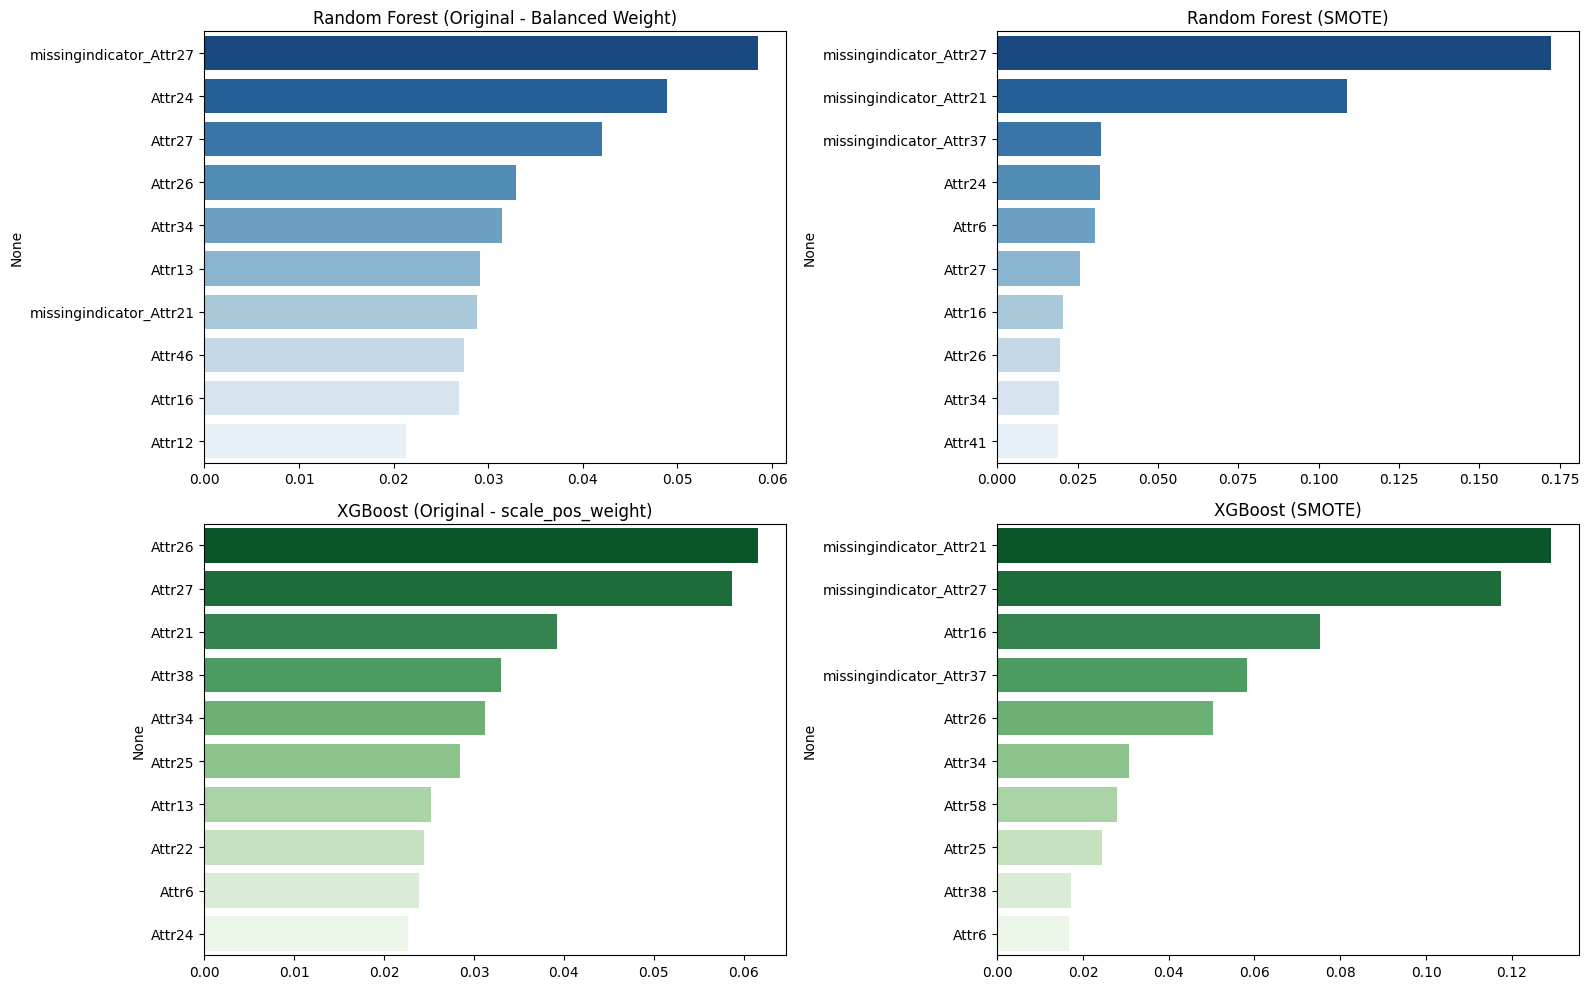

In [59]:
# Extract Top 10 Features for all 4 models
rf_orig_imp  = pd.Series(rf_clf_orig.feature_importances_, index=X_train_tree.columns).nlargest(10)
rf_smote_imp = pd.Series(rf_clf_smote.feature_importances_, index=X_train_tree.columns).nlargest(10)

xgb_orig_imp  = pd.Series(xgb_clf_orig.feature_importances_, index=X_train_xgboost.columns).nlargest(10)
xgb_smote_imp = pd.Series(xgb_clf_smote.feature_importances_, index=X_train_tree.columns).nlargest(10)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. RF Original
sns.barplot(x=rf_orig_imp.values, y=rf_orig_imp.index, hue=rf_orig_imp.index, legend=False, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title("Random Forest (Original - Balanced Weight)", fontsize=12)

# 2. RF SMOTE
sns.barplot(x=rf_smote_imp.values, y=rf_smote_imp.index, hue=rf_smote_imp.index, legend=False, ax=axes[0, 1], palette='Blues_r')
axes[0, 1].set_title("Random Forest (SMOTE)", fontsize=12)

# 3. XGBoost Original
sns.barplot(x=xgb_orig_imp.values, y=xgb_orig_imp.index, hue=xgb_orig_imp.index, legend=False, ax=axes[1, 0], palette='Greens_r')
axes[1, 0].set_title("XGBoost (Original - scale_pos_weight)", fontsize=12)

# 4. XGBoost SMOTE
sns.barplot(x=xgb_smote_imp.values, y=xgb_smote_imp.index, hue=xgb_smote_imp.index, legend=False, ax=axes[1, 1], palette='Greens_r')
axes[1, 1].set_title("XGBoost (SMOTE)", fontsize=12)

plt.tight_layout()
plt.show()

### Feature Importance Analysis Across Models

To understand the underlying decision-making criteria of the trained classifiers, feature importance scores were extracted and compared across both original and SMOTE-resampled variants of the Random Forest and XGBoost architectures.

### 1. Random Forest Models

- Original (Balanced Weight): On the un-resampled dataset, feature importance is dominated by missingindicator_Attr27 (importance score $\approx 0.058$), followed by numerical profitability ratios Attr24 (gross profit over 3 years / total assets) and Attr27 (operating profit / financial expenses). The presence of missingness indicators in the top tier confirms that non-reporting behavior provides strong signals to tree splits.

- SMOTE: When trained on SMOTE-generated samples, missingness indicators take an overwhelming lead. missingindicator_Attr27 leads with an importance score exceeding 0.17, followed by missingindicator_Attr21 (sales growth rate) at 0.11. By synthetically expanding the minority class, the Random Forest model heavily leverages missing data patterns alongside key cash flow ratios like Attr24 and Attr6 (retained earnings / total assets).

### 2. XGBoost Models

- Original (scale_pos_weight): In the unsampled XGBoost model, numerical leverage and solvency ratios dominate the top rankings, led by Attr26 ((net profit + depreciation) / total liabilities) and Attr27, both scoring near 0.06. XGBoost’s gradient-boosting mechanism relies heavily on numerical thresholds of debt coverage and operating efficiency (e.g., Attr21, Attr38, and Attr34) to separate operating firms from failing ones.

- SMOTE (30/70): Introducing SMOTE to XGBoost dramatically shifts the model's focus toward missingness signals. missingindicator_Attr21 and missingindicator_Attr27 emerge as the two most critical features (importance scores of 0.13 and 0.117, respectively), followed by Attr16 (gross profit + depreciation / total liabilities) and missingindicator_Attr37.

### Synthesis & Domain Insights

Across all four models, the feature importance hierarchy clearly shows that missing values are not noise, but predictive signals. Companies that omit reporting interest coverage (Attr27) or revenue growth (Attr21) carry significantly higher structural risks. When combining these missingness flags with core accounting metrics—specifically cash flow solvency ratios (Attr26, Attr24, Attr16)—the ensemble models effectively isolate the primary triggers of corporate distress.


## Final Model Comparison

To evaluate the overall efficacy of the modeling pipeline, the top-performing linear baseline—L1 Regularized Logistic Regression—was benchmarked against the top-performing non-linear tree ensemble—Original XGBoost—evaluated on the identical 2,084-observation test set. In highly imbalanced binary classification tasks where minority events comprise just $4.7\%$ of the dataset, Precision-Recall AUC (PR-AUC) serves as the primary metric of predictive power. On this metric, Original XGBoost achieved a PR-AUC of 53.13%, nearly tripling the 19.44% recorded by L1 Logistic Regression. XGBoost also demonstrated superior overall class separation, securing an ROC-AUC score of 89.27% compared to the linear model's 77.39%—an absolute improvement of nearly 12 percentage points.

The primary divergence between the two architectures lies in how they manage the trade-off between precision and recall. While L1 Logistic Regression achieved a slightly higher raw recall at standard cutoffs (54.55% vs. 48.48%, catching 54 of 99 true bankruptcies compared to XGBoost's 48), it did so at the cost of severe false-positive inflation. The linear model generated 245 false alarms, which diluted its minority-class precision down to a meager 18.00% (fewer than one in five flagged companies were actually distressed). Conversely, Original XGBoost generated only 47 false alarms—an 80.8% reduction in false positives—pushing minority precision up to 50.53%. This drastic reduction in false alarms allowed XGBoost to achieve an overall minority F1-score of 0.4948, nearly doubling the 0.2700 F1-score of the L1 baseline.

These results highlight the structural limitations of linear modeling when applied to complex financial ratio distributions. Even after L1 regularization drove 11 redundant features to zero, Logistic Regression struggled to construct an effective hyperplanar boundary through heavily skewed, non-linear accounting data. XGBoost, by contrast, leveraged exact greedy decision splits to isolate missingness indicators and capture non-linear interactions between cash flow and debt metrics without being overwhelmed by majority-class bias.

In domain-specific risk management, however, recall is the ultimate metric of model survivability. Corporate bankruptcy prediction inherently operates under severe cost asymmetry: missing a failing firm (False Negative) results in total default exposure, write-offs, and severe financial losses, whereas auditing a healthy firm (False Positive) incurs only minor operational overhead. Therefore, a risk-averse institution must prioritize maximizing recall above all else to ensure the system captures as many impending collapses as possible before they occur. While Logistic Regression appears competitive on default recall at standard cutoffs ($54.55\%$), its high false-alarm rate reflects an uncalibrated, noisy boundary rather than true failure extraction power.

Ultimately, deploying XGBoost under a risk-averse framework unlocks its full recall potential. By recalibrating Original XGBoost's decision threshold from the default $0.50$ down to $0.15$, the model's sensitivity skyrockets—capturing $80.81\%$ of all true bankruptcies (80 out of 99 failing firms), representing a massive 26-percentage-point surge in failure retrieval over the linear model's baseline recall. Remarkably, even at this hyper-sensitive threshold tuned for maximum recall, XGBoost maintains higher precision ($19.66\%$) than Logistic Regression did at its standard operating point. Consequently, whether evaluated for general screening or strict risk-mitigation where missing a default is non-negotiable, XGBoost stands out as the definitively superior model.